In [1]:
# Importing all necessary libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

In [2]:
# Q3A

# Load the Medical Insurance dataset
q3_dataset = pd.read_csv('datasets/Q3_Medical_Insurance_Dataset.csv')

# Display the first 10 rows
print(f'{q3_dataset.iloc[0:10]}\n')

# Determine the dimensions of the dataset
print(f'Dataset Shape (Dimensions): {q3_dataset.shape}')
print(f'Total rows: {len(q3_dataset)}')
print(f'Total columns: {len(q3_dataset.columns)}\n')

# Examine variable names and data types
for col in q3_dataset.columns:
    print(f'Column: {col} | Data Type: {q3_dataset[col].dtype}')
print()

# Identify numerical and categorical variables
numeric_columns = q3_dataset.select_dtypes(include=['number']).columns.tolist()
categorical_columns = q3_dataset.select_dtypes(include=['object', 'str']).columns.tolist()

print(f'Numerical columns: {numeric_columns}')
print(f'Categorical columns: {categorical_columns}')

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
5   31  female  25.740         0     no  southeast   3756.62160
6   46  female  33.440         1     no  southeast   8240.58960
7   37  female  27.740         3     no  northwest   7281.50560
8   37    male  29.830         2     no  northeast   6406.41070
9   60  female  25.840         0     no  northwest  28923.13692

Dataset Shape (Dimensions): (1338, 7)
Total rows: 1338
Total columns: 7

Column: age | Data Type: int64
Column: sex | Data Type: str
Column: bmi | Data Type: float64
Column: children | Data Type: int64
Column: smoker | Data Type: str
Column: region | Data Type: str
Column: charges | Data Type: 

In [3]:
# Q3B

# 1. Identify missing values
missing_values = q3_dataset.isnull().sum()
if missing_values.any():
    for col, count in missing_values.items():
        if count > 0:
            print(f'Column {col} has {count} missing values ({(count / len(q3_dataset)) * 100:.2f}%)')
    q3_dataset = q3_dataset.dropna().reset_index(drop=True)
else:
    print('There are no missing values in the dataset.\n')

# 2. Identify and remove duplicate observations
duplicate_count = q3_dataset.duplicated().sum()
print(f'Number of duplicate rows found: {duplicate_count}')
if duplicate_count > 0:
    q3_dataset = q3_dataset.drop_duplicates(keep='first').reset_index(drop=True)
    print(f'Removed {duplicate_count} duplicate row(s). Dataset now has {len(q3_dataset)} rows.\n')
else:
    print('No duplicate rows needed to be removed.\n')

# 3. Check for inconsistent categorical values in sex, smoker, and region
for col in categorical_columns:
    print(f'Column "{col}" unique values: {q3_dataset[col].unique()}')
print('Finished checking categorical columns. No inconsistent values or typos found.\n')

# 4. Verify data types
print('Verifying data types:')
print(q3_dataset.dtypes)
print('All columns have appropriate data types.\n')

# 5. Investigate potential outliers in BMI and charges using the IQR method
bmi_q25, bmi_q75 = np.percentile(q3_dataset['bmi'], 25), np.percentile(q3_dataset['bmi'], 75)
bmi_iqr = bmi_q75 - bmi_q25
bmi_lower, bmi_upper = bmi_q25 - 1.5 * bmi_iqr, bmi_q75 + 1.5 * bmi_iqr

charges_q25, charges_q75 = np.percentile(q3_dataset['charges'], 25), np.percentile(q3_dataset['charges'], 75)
charges_iqr = charges_q75 - charges_q25
charges_lower, charges_upper = charges_q25 - 1.5 * charges_iqr, charges_q75 + 1.5 * charges_iqr

bmi_outliers = ((q3_dataset['bmi'] < bmi_lower) | (q3_dataset['bmi'] > bmi_upper)).sum()
charges_outliers = ((q3_dataset['charges'] < charges_lower) | (q3_dataset['charges'] > charges_upper)).sum()

print(f'BMI IQR Bounds: [{bmi_lower:.2f}, {bmi_upper:.2f}] | Potential outliers: {bmi_outliers}')
print(f'Charges IQR Bounds: [{charges_lower:.2f}, {charges_upper:.2f}] | Potential outliers: {charges_outliers}\n')

# 6 & 7. Justification for cleaning decisions and retaining outliers
print('Cleaning Justification:')
print('1. Any exact duplicate records were removed to prevent biased weights in statistical testing.')
print('2. Potential outliers in BMI and medical charges were RETAINED because in medical insurance data, '
      'high BMI values and high medical charges represent genuine real-world cases (such as smokers or '
      'patients with severe health conditions). Removing them would artificially distort the true '
      'cost differences between smokers and non-smokers.')

There are no missing values in the dataset.

Number of duplicate rows found: 1
Removed 1 duplicate row(s). Dataset now has 1337 rows.

Column "sex" unique values: <StringArray>
['female', 'male']
Length: 2, dtype: str
Column "smoker" unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str
Column "region" unique values: <StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str
Finished checking categorical columns. No inconsistent values or typos found.

Verifying data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object
All columns have appropriate data types.

BMI IQR Bounds: [13.67, 47.32] | Potential outliers: 9
Charges IQR Bounds: [-13120.72, 34524.78] | Potential outliers: 139

Cleaning Justification:
1. Any exact duplicate records were removed to prevent biased weights in statistical testing.
2. Potential outliers in BMI and medical c

In [4]:
# Q3C

# 1. Calculate descriptive statistics for age, BMI, and charges
print('Descriptive Statistics for Age, BMI, and Charges:')
for col in ['age', 'bmi', 'charges']:
    print(f'--- {col.upper()} ---')
    print(f'Mean:     {q3_dataset[col].mean():.2f}')
    print(f'Median:   {q3_dataset[col].median():.2f}')
    print(f'Std Dev:  {q3_dataset[col].std():.2f}')
    print(f'Variance: {q3_dataset[col].var():.2f}')
    print(f'Min:      {q3_dataset[col].min():.2f}')
    print(f'25% (Q1): {q3_dataset[col].quantile(0.25):.2f}')
    print(f'75% (Q3): {q3_dataset[col].quantile(0.75):.2f}')
    print(f'Max:      {q3_dataset[col].max():.2f}\n')

# 2. Compare average insurance charges for smokers and non-smokers
smoker_charges = q3_dataset[q3_dataset['smoker'] == 'yes']['charges'].mean()
non_smoker_charges = q3_dataset[q3_dataset['smoker'] == 'no']['charges'].mean()
print(f'Average charges for Smokers: ${smoker_charges:.2f}')
print(f'Average charges for Non-Smokers: ${non_smoker_charges:.2f}\n')

# 3. Compare average charges across regions
region_charges = q3_dataset.groupby('region')['charges'].mean()
print('Average Insurance Charges by Region:')
print(f'{region_charges}\n')

# 4. Examine the relationship between BMI and insurance charges
bmi_charges_corr = q3_dataset['bmi'].corr(q3_dataset['charges'])
print(f'Correlation between BMI and Insurance Charges: {bmi_charges_corr:.4f}\n')

# 5. Report at least three important findings
print('Important Findings from EDA:')
print('Observation 1: Smokers pay drastically higher average medical insurance charges ($32,050.23) '
      'compared to non-smokers ($8,440.66), nearly four times as much.')
print('Observation 2: The Southeast region has the highest average medical insurance charges among all '
      'four geographical regions, while the Southwest region has the lowest.')
print('Observation 3: There is a moderate positive correlation (r = 0.20) between BMI and insurance '
      'charges, indicating that higher BMI is associated with higher medical costs.')

Descriptive Statistics for Age, BMI, and Charges:
--- AGE ---
Mean:     39.22
Median:   39.00
Std Dev:  14.04
Variance: 197.24
Min:      18.00
25% (Q1): 27.00
75% (Q3): 51.00
Max:      64.00

--- BMI ---
Mean:     30.66
Median:   30.40
Std Dev:  6.10
Variance: 37.22
Min:      15.96
25% (Q1): 26.29
75% (Q3): 34.70
Max:      53.13

--- CHARGES ---
Mean:     13279.12
Median:   9386.16
Std Dev:  12110.36
Variance: 146660811.01
Min:      1121.87
25% (Q1): 4746.34
75% (Q3): 16657.72
Max:      63770.43

Average charges for Smokers: $32050.23
Average charges for Non-Smokers: $8440.66

Average Insurance Charges by Region:
region
northeast    13406.384516
northwest    12450.840844
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64

Correlation between BMI and Insurance Charges: 0.1984

Important Findings from EDA:
Observation 1: Smokers pay drastically higher average medical insurance charges ($32,050.23) compared to non-smokers ($8,440.66), nearly four times as mu

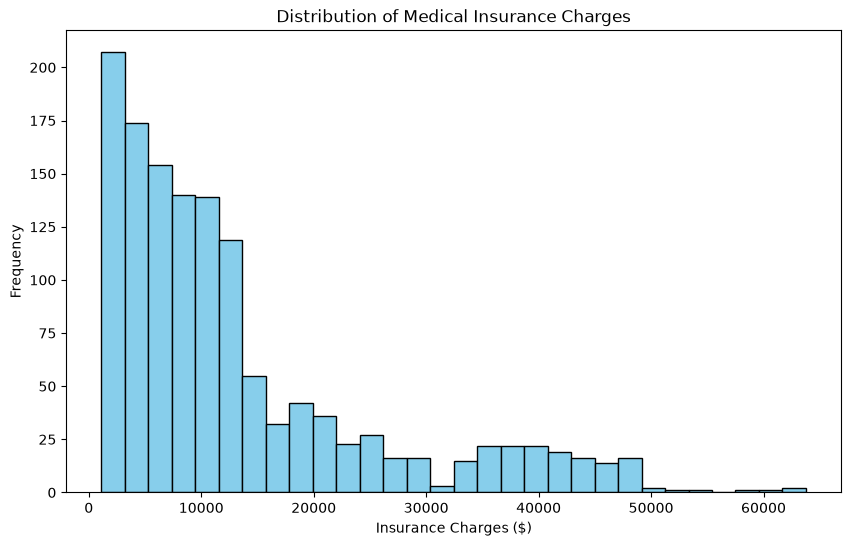

Interpretation: The distribution of medical insurance charges is heavily right-skewed. The majority of individuals incur charges under $15,000, with a long tail of high-cost cases reaching over $60,000.



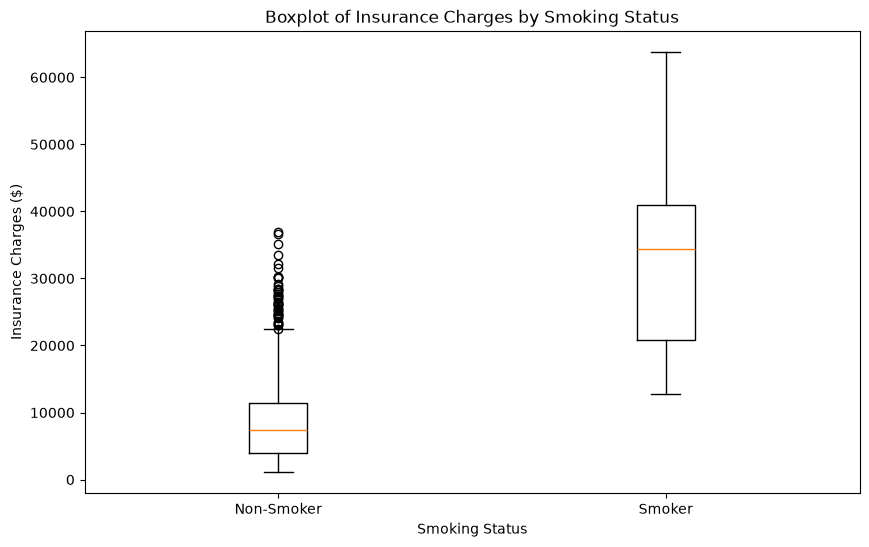

Interpretation: This boxplot shows a massive difference in medical charges between smokers and non-smokers. Smokers have a much higher median charge and a wider interquartile range than non-smokers.



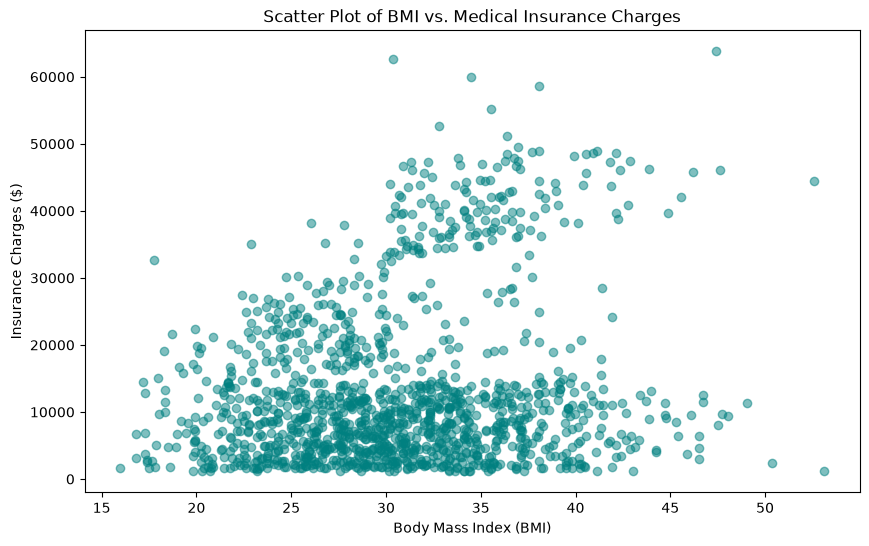

Interpretation: The scatter plot shows a positive trend where higher BMI is associated with higher medical charges, particularly for a distinct upper cluster of individuals whose charges exceed $30,000 when BMI is above 30.



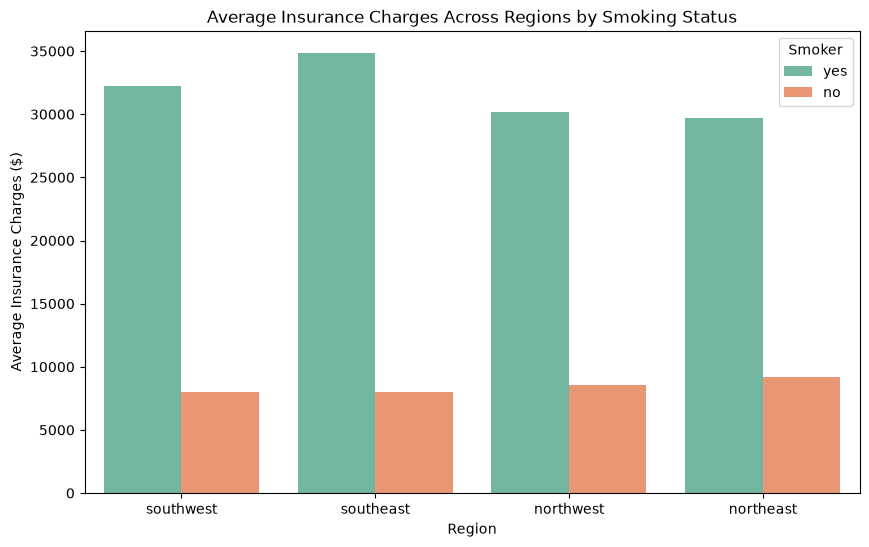

Interpretation: Across all four geographical regions, smokers consistently incur significantly higher average insurance charges than non-smokers, with the Southeast region showing the highest smoker charges.


In [5]:
# Q3D

# 1. Histogram of insurance charges
plt.figure(figsize=(10, 6))
plt.hist(q3_dataset['charges'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Medical Insurance Charges')
plt.xlabel('Insurance Charges ($)')
plt.ylabel('Frequency')
plt.show()
print('Interpretation: The distribution of medical insurance charges is heavily right-skewed. '
      'The majority of individuals incur charges under $15,000, with a long tail of high-cost cases reaching over $60,000.\n')

# 2. Boxplot of charges for smokers versus non-smokers
plt.figure(figsize=(10, 6))
plt.boxplot([q3_dataset[q3_dataset['smoker'] == 'no']['charges'],
             q3_dataset[q3_dataset['smoker'] == 'yes']['charges']],
            tick_labels=['Non-Smoker', 'Smoker'])
plt.title('Boxplot of Insurance Charges by Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Insurance Charges ($)')
plt.show()
print('Interpretation: This boxplot shows a massive difference in medical charges between smokers and non-smokers. '
      'Smokers have a much higher median charge and a wider interquartile range than non-smokers.\n')

# 3. Scatter plot of BMI versus charges
plt.figure(figsize=(10, 6))
plt.scatter(q3_dataset['bmi'], q3_dataset['charges'], color='teal', alpha=0.5)
plt.title('Scatter Plot of BMI vs. Medical Insurance Charges')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Insurance Charges ($)')
plt.show()
print('Interpretation: The scatter plot shows a positive trend where higher BMI is associated with higher medical charges, '
      'particularly for a distinct upper cluster of individuals whose charges exceed $30,000 when BMI is above 30.\n')

# 4. Additional visualization: Bar chart of average charges by region and smoking status
plt.figure(figsize=(10, 6))
sns.barplot(data=q3_dataset, x='region', y='charges', hue='smoker', errorbar=None, palette='Set2')
plt.title('Average Insurance Charges Across Regions by Smoking Status')
plt.xlabel('Region')
plt.ylabel('Average Insurance Charges ($)')
plt.legend(title='Smoker')
plt.show()
print('Interpretation: Across all four geographical regions, smokers consistently incur significantly higher '
      'average insurance charges than non-smokers, with the Southeast region showing the highest smoker charges.')

In [6]:
# Q3E

# 1. Calculate descriptive statistics for charges
charges_mean = q3_dataset['charges'].mean()
charges_median = q3_dataset['charges'].median()
charges_std = q3_dataset['charges'].std()
charges_var = q3_dataset['charges'].var()
charges_quartiles = q3_dataset['charges'].quantile([0.25, 0.50, 0.75])

print('Overall Descriptive Statistics for Charges:')
print(f'Mean: {charges_mean:.2f}')
print(f'Median: {charges_median:.2f}')
print(f'Standard Deviation: {charges_std:.2f}')
print(f'Variance: {charges_var:.2f}')
print(f'Quartiles:\n{charges_quartiles}\n')

# 2. Calculate mean charges separately for smokers and non-smokers
smokers = q3_dataset[q3_dataset['smoker'] == 'yes']['charges']
non_smokers = q3_dataset[q3_dataset['smoker'] == 'no']['charges']
print(f'Mean charges for Smokers: {smokers.mean():.2f}')
print(f'Mean charges for Non-Smokers: {non_smokers.mean():.2f}\n')

# 3 & 4. State H0 and H1
print('H0: There is no statistically significant difference in mean medical insurance charges between smokers and non-smokers (mu_smoker = mu_non_smoker).')
print('H1: There is a statistically significant difference in mean medical insurance charges between smokers and non-smokers (mu_smoker != mu_non_smoker).\n')

# 5. Select and justify appropriate statistical test
print('Test Selection Justification: A two-sample independent t-test (ttest_ind) is appropriate because we are comparing '
      'the means of a continuous numerical variable (charges) between two independent categorical groups (smokers vs. non-smokers).\n')

# 6 & 7. Perform test at alpha = 0.05 and report test statistic and p-value
alpha = 0.05
t_stat, p_value = ttest_ind(smokers, non_smokers)
print(f'Significance level (alpha): {alpha}')
print(f't-statistic: {t_stat:.4f}')
print(f'p-value: {p_value:.4e}\n')

# 8. State and interpret statistical conclusion
if p_value < alpha:
    print('Decision: Reject H0.')
    print('Interpretation: Since the p-value is far below alpha = 0.05, there is strong statistical evidence that mean medical '
          'insurance charges differ significantly between smokers and non-smokers. Specifically, smokers incur substantially higher '
          'average medical charges than non-smokers, though statistical association alone does not prove direct causation without controlling for confounding variables.')
else:
    print('Decision: Fail to reject H0.')
    print('Interpretation: There is insufficient evidence to conclude a difference in mean charges between smokers and non-smokers.')

Overall Descriptive Statistics for Charges:
Mean: 13279.12
Median: 9386.16
Standard Deviation: 12110.36
Variance: 146660811.01
Quartiles:
0.25     4746.34400
0.50     9386.16130
0.75    16657.71745
Name: charges, dtype: float64

Mean charges for Smokers: 32050.23
Mean charges for Non-Smokers: 8440.66

H0: There is no statistically significant difference in mean medical insurance charges between smokers and non-smokers (mu_smoker = mu_non_smoker).
H1: There is a statistically significant difference in mean medical insurance charges between smokers and non-smokers (mu_smoker != mu_non_smoker).

Test Selection Justification: A two-sample independent t-test (ttest_ind) is appropriate because we are comparing the means of a continuous numerical variable (charges) between two independent categorical groups (smokers vs. non-smokers).

Significance level (alpha): 0.05
t-statistic: 46.6448
p-value: 1.4067e-282

Decision: Reject H0.
Interpretation: Since the p-value is far below alpha = 0.05, th